# 04 · Score the model fixes (compile them)

**Metrics**
- **Compiles:** the fixed code builds with `dotnet build`.
- **Faithful fix (main score):** compiles, *no original line deleted*, at most 2 lines different from the original.
- **Exact:** identical to the original code (ignoring spacing and blank lines).

"No deleted lines" stops a model from "fixing" an error by deleting the broken line, which compiles but removes the feature.

## 1. Setup

In [1]:
# Cell 3: Setup.
import sys                                              # To add the project folder to Python's import path
from pathlib import Path                                # File paths that work on any OS

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # Project folder, wherever it lives
sys.path.insert(0, str(ROOT))                           # So our .py files can be imported

import pandas as pd                                     # Tables
from scoring import score, summary                      # Our scoring functions

EVAL_FILE = ROOT / "data" / "processed" / "test_eval.jsonl"   # The 200 evaluation examples
EVALS = ROOT / "evals"                                  # Predictions downloaded from Drive, and scored results
pd.set_option("display.max_colwidth", 100)              # Show longer text in table cells
print("Predictions found:", sorted(p.name for p in EVALS.glob("preds_*.jsonl")))

Predictions found: ['preds_base.jsonl', 'preds_finetuned.jsonl']


## 2. Score the base model
Compiles all 200 predictions (about 1 minute with 4 parallel sandboxes).

In [2]:
# Cell 5: Compile and score the base model's fixes.
base = score(EVALS / "preds_base.jsonl", EVAL_FILE)      # One row per example with all metrics
base.to_json(EVALS / "scored_base.jsonl", orient="records", lines=True, force_ascii=False)   # Save for later comparison
pd.DataFrame([summary(base, "base (Qwen2.5-Coder-1.5B)")])   # Headline metrics

100%|██████████| 200/200 [05:36<00:00,  1.68s/it]


,model,examples,compiles,faithful fix,exact,deleted code,returned broken,median changed lines
0,base (Qwen2.5-Coder-1.5B),200,66%,46%,22%,16%,2%,2.0


## 3. Per operator
Which kinds of mistakes the base model can and cannot fix.

In [3]:
# Cell 7: Metrics per main operator.
per_op = base.groupby("operator")[["compiles", "faithful_fix", "exact"]].mean().mul(100).round(0).astype(int)
per_op["n"] = base.groupby("operator").size()           # How many examples of each
per_op.sort_values("faithful_fix")                      # Hardest first

,compiles,faithful_fix,exact,n
operator,,,,
drop_async,33,0,0,3
remove_using,33,17,8,12
wrong_local,57,33,19,21
wrong_type,56,38,24,34
wrong_member,69,50,24,42
drop_semicolon,75,50,28,32
wrong_literal,79,57,14,14
drop_closing,76,61,24,33
drop_new,78,67,22,9


## 4. How the base model fails
Answers that compile but changed too much, answers that deleted code, and answers that still don't compile.

In [4]:
# Cell 9: Count the failure types and show one example of each.
fails = base[~base["faithful_fix"]]                     # Everything that isn't a faithful fix
kinds = {"still doesn't compile": fails[~fails["compiles"]],
         "compiles, but deleted code": fails[fails["compiles"] & (fails["deleted"] > 0)],
         "compiles, but changed > 2 lines": fails[fails["compiles"] & (fails["deleted"] == 0)]}
for label, part in kinds.items():
    print(f"{label:<34} {len(part):>3}")
for label, part in kinds.items():                       # One example of each failure type
    if len(part):
        r = part.iloc[0]
        print(f"\n===== {label}: {r['id']} ({r['kinds']}) | changed {r['changed']}, deleted {r['deleted']}")
        print(r["new_errors"] or r["pred"][:600])       # Compiler errors, or the start of the answer

still doesn't compile               68
compiles, but deleted code           8
compiles, but changed > 2 lines     31

===== still doesn't compile: ex_00947 (wrong_type) | changed 6, deleted 0
Line 17: error CS0103: The name 'ForwardedHeaders' does not exist in the current context
    > ForwardedHeaders = ForwardedHeaders.XForwardedFor | ForwardedHeaders.XForwardedProto

===== compiles, but deleted code: ex_02075 (wrong_literal) | changed 3, deleted 4
var builder = WebApplication.CreateBuilder(args);

var app = builder.Build();

// Examine Hosting environment: logging value
app.Logger.LogInformation("ASPNETCORE_ENVIRONMENT: {env}",
      Environment.GetEnvironmentVariable("ASPNETCORE_ENVIRONMENT"));

app.Logger.LogInformation("app.Environment.IsDevelopment(): {env}",
      app.Environment.IsDevelopment().ToString());

app.UseDefaultFiles();
app.UseStaticFiles();

app.Run();


===== compiles, but changed > 2 lines: ex_01943 (wrong_member) | changed 4, deleted 0
using Microsoft.Extensions

## 5. Score the fine-tuned model
Same 200 examples, same scoring as the base model.

In [5]:
# Cell 11: Compile and score the fine-tuned model's fixes, then compare with the base model.
base = pd.read_json(EVALS / "scored_base.jsonl", lines=True)            # Base results (saved by Cell 5)
ft = score(EVALS / "preds_finetuned.jsonl", EVAL_FILE)   # Compile all 200 fine-tuned answers
ft.to_json(EVALS / "scored_finetuned.jsonl", orient="records", lines=True, force_ascii=False)   # Save for the README
comparison = pd.DataFrame([summary(base, "base (Qwen2.5-Coder-1.5B)"),
                           summary(ft, "fine-tuned (QLoRA, 25 min T4)")])
comparison.to_csv(ROOT / "reports" / "comparison.csv", index=False)     # The headline table for the README
comparison

100%|██████████| 200/200 [03:54<00:00,  1.17s/it]


,model,examples,compiles,faithful fix,exact,deleted code,returned broken,median changed lines
0,base (Qwen2.5-Coder-1.5B),200,66%,46%,22%,16%,2%,2.0
1,"fine-tuned (QLoRA, 25 min T4)",200,96%,94%,90%,3%,0%,0.0


## 6. Per operator: base vs fine-tuned
Faithful-fix rate (%) for each kind of mistake.

In [6]:
# Cell 13: Faithful-fix rate per operator, side by side.
per_op = pd.DataFrame({
    "n": ft.groupby("operator").size(),                                        # Examples per operator
    "base %": base.groupby("operator")["faithful_fix"].mean().mul(100).round(0),
    "fine-tuned %": ft.groupby("operator")["faithful_fix"].mean().mul(100).round(0)})
per_op["gain"] = per_op["fine-tuned %"] - per_op["base %"]     # Percentage points gained
per_op.astype(int).sort_values("fine-tuned %")                # Weakest first

,n,base %,fine-tuned %,gain
operator,,,,
remove_using,12,17,42,25
drop_new,9,67,89,22
drop_semicolon,32,50,97,47
drop_closing,33,61,97,36
wrong_member,42,50,98,48
drop_async,3,0,100,100
wrong_literal,14,57,100,43
wrong_local,21,33,100,67
wrong_type,34,38,100,62


## 7. What the fine-tuned model still gets wrong
Every example that isn't a faithful fix, plus any example the *base* model fixed but the fine-tuned model didn't (a regression).

In [7]:
# Cell 15: Remaining failures and regressions.
m = base[["id", "faithful_fix"]].merge(ft[["id", "faithful_fix"]], on="id", suffixes=("_base", "_ft"))   # Per example, both models
print(f"Both fixed: {(m.faithful_fix_base & m.faithful_fix_ft).sum()} | only fine-tuned: {(~m.faithful_fix_base & m.faithful_fix_ft).sum()} "
      f"| only base (regressions): {(m.faithful_fix_base & ~m.faithful_fix_ft).sum()} | neither: {(~m.faithful_fix_base & ~m.faithful_fix_ft).sum()}")

fails = ft[~ft["faithful_fix"]]                         # Everything the fine-tuned model didn't fix faithfully
print(f"\nFine-tuned failures: {len(fails)}")
for _, r in fails.iterrows():                           # Short report for each one
    status = "doesn't compile" if not r["compiles"] else f"compiles, changed {r['changed']}, deleted {r['deleted']}"
    print(f"\n=== {r['id']} | {r['kinds']} | errors {r['error_codes'][:2]} | {status}")
    if r["new_errors"]:
        print(r["new_errors"][:300])                    # What the compiler says about the fine-tuned answer

Both fixed: 91 | only fine-tuned: 98 | only base (regressions): 2 | neither: 9

Fine-tuned failures: 11

=== ex_00771 | remove_using | errors ['CS0103'] | doesn't compile
Line 62: error CS0103: The name 'MediaTypeNames' does not exist in the current context
    > builder.Metadata.Add(new ProducesAttribute(MediaTypeNames.Text.Html));

=== ex_02326 | remove_using+drop_semicolon | errors ['CS1002'] | doesn't compile
Line 44: error CS0246: The type or namespace name 'Hub' could not be found (are you missing a using directive or an assembly reference?)
    > public class MyHub : Hub

=== ex_02323 | remove_using | errors ['CS0246'] | compiles, changed 1, deleted 1

=== ex_00768 | drop_closing | errors ['CS1026'] | doesn't compile
Line 29: error CS1026: ) expected
    > => orderId > 999 ? TypedResults.BadRequest() : TypedResults.Ok(new Order(orderId));

=== ex_00247 | drop_semicolon+drop_async | errors ['CS1003'] | doesn't compile
Line 24: error CS4032: The 'await' operator can only be used w

## 8. Chart: faithful-fix rate per operator
Saved to `reports/per_operator.png` for the README.

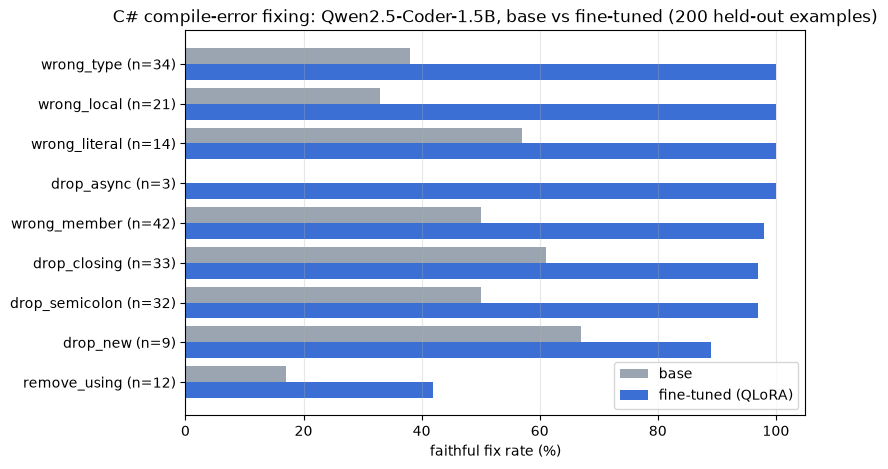

In [8]:
# Cell 17: Horizontal bar chart, base vs fine-tuned, per operator.
import matplotlib.pyplot as plt                         # Charts

order = per_op.sort_values("fine-tuned %").index        # Weakest (after fine-tuning) at the bottom
y = range(len(order))                                   # One row per operator
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([i + 0.2 for i in y], per_op.loc[order, "base %"], height=0.4, label="base", color="#9aa5b1")
ax.barh([i - 0.2 for i in y], per_op.loc[order, "fine-tuned %"], height=0.4, label="fine-tuned (QLoRA)", color="#3b6fd4")
ax.set_yticks(list(y))
ax.set_yticklabels([f"{op} (n={per_op.loc[op, 'n']})" for op in order])   # Show how many examples each bar is based on
ax.set_xlabel("faithful fix rate (%)")
ax.set_xlim(0, 105)
ax.set_title("C# compile-error fixing: Qwen2.5-Coder-1.5B, base vs fine-tuned (200 held-out examples)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.savefig(ROOT / "reports" / "per_operator.png", dpi=150, bbox_inches="tight")   # For the README
plt.show()

## 9. Real-world errors: Project 3 build failures
Real mistakes made by an LLM (gpt-oss-120b) while writing ASP.NET Core code, not created by our mutation operators.
There is no reference answer, so the score is: does the fix compile, and does it look right on inspection.
"Seen" = a correct version of the same task was a training seed (the model may remember it).

In [9]:
# Cell 19: Build a small real-error set from Project 3's failed builds, with a leakage flag.
from csharp import compile_code                         # Re-build to get the errors in our format

SYSTEM_PROMPT = ("You fix C# compiler errors in ASP.NET Core Program.cs files. "
                 "Return the complete corrected file in one ```csharp block. Change only what is needed to fix the errors.")   # Same as training
P3 = ROOT.parent / "aspnetcore-coding-agents" / "evals" # Project 3 results
seeds = pd.read_json(ROOT / "data" / "processed" / "seeds.jsonl", lines=True)
train = pd.read_json(ROOT / "data" / "processed" / "train.jsonl", lines=True)
train_groups = set(seeds.set_index("id").loc[train["seed_id"].unique(), "group"])   # Source groups used in training

real = []
for f in sorted(P3.glob("results_*.jsonl")):            # Baseline, team v1, team v2 (whatever exists)
    for r in pd.read_json(f, lines=True).to_dict("records"):
        if r["build_ok"] or not r["code"]:              # Only code that failed to compile
            continue
        b = compile_code(r["code"])                     # Errors in the same format the model was trained on
        if b.succeeded:                                 # (Should not happen, but skip if it now builds)
            continue
        errors = b.error_text(r["code"])
        user = f"Compiler errors:\n{errors}\n\nCode:\n```csharp\n{r['code']}\n```"
        real.append({"id": f"{f.stem}/{r['id']}", "task": r["id"], "broken": r["code"], "errors": errors,
                     "seen": f"p3/{r['id']}" in train_groups,   # Leakage flag
                     "messages": [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]})

real_df = pd.DataFrame(real)
real_df.to_json(ROOT / "data" / "processed" / "real_errors.jsonl", orient="records", lines=True, force_ascii=False)
print(f"Real errors: {len(real_df)}")
print(real_df[["id", "seen"]].to_string(index=False))
for e in real_df["errors"]:
    print("\n" + e.splitlines()[0][:150])               # First error of each, shortened

Real errors: 4
                           id  seen
results_baseline/output_cache False
      results_team/rate_limit  True
results_team/typed_httpclient  True
    results_team/output_cache False

Line 12: error CS1061: 'OutputCachePolicyBuilder' does not contain a definition for 'Expiration' and no accessible extension method 'Expiration' accep

Line 20: error CS0103: The name 'RateLimiterPartition' does not exist in the current context

Line 21: error CS1503: Argument 3: cannot convert from 'int' to 'System.Text.Encoding?'

Line 16: error CS1061: 'OutputCachePolicyBuilder' does not contain a definition for 'WithDuration' and no accessible extension method 'WithDuration' a


# Cell 20: Fine-tuned AND base model on the real errors (the base = same model with the adapter switched off).
real_rows = pd.read_json(DATA / "real_errors.jsonl", lines=True).to_dict("records")   # Project 3's real build failures
run_eval("finetuned", real_rows, EVALS / "preds_real_finetuned.jsonl")   # With our LoRA adapter
with model.disable_adapter():                           # Temporarily switch the adapter off = the original base model
    run_eval("base", real_rows, EVALS / "preds_real_base.jsonl")

In [11]:
# Cell 21: Compile both models' fixes of the real errors and show what changed.
import difflib                                          # Show the changes
from csharp import compile_many                         # Parallel builds

for name in ("base", "finetuned"):
    p = pd.read_json(EVALS / f"preds_real_{name}.jsonl", lines=True).merge(real_df[["id", "seen", "broken"]], on="id")
    ok = [r.succeeded for r in compile_many(p["pred"].tolist())]   # Does each fix compile?
    print(f"\n######## {name}: compiles {sum(ok)}/{len(p)}")
    for (_, r), good in zip(p.iterrows(), ok):
        print(f"\n=== {r['id']} | {'seen' if r['seen'] else 'unseen'} | {'COMPILES' if good else 'does not compile'}")
        diff = difflib.unified_diff(r["broken"].splitlines(), r["pred"].splitlines(), lineterm="", n=0)
        for line in [l for l in diff if l[:1] in "+-" and not l.startswith(("+++", "---"))][:6]:
            print("   ", line.strip()[:120])            # The lines the model changed

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:12<00:00,  3.00s/it]



######## base: compiles 0/4

=== results_baseline/output_cache | unseen | does not compile
    -using Microsoft.AspNetCore.OutputCaching;
    +using Microsoft.AspNetCore.Builder;
    +using Microsoft.AspNetCore.Hosting;
    +using Microsoft.Extensions.DependencyInjection;
    +using Microsoft.Extensions.Hosting;
    +using System.Diagnostics.CodeAnalysis;

=== results_team/rate_limit | seen | does not compile

=== results_team/typed_httpclient | seen | does not compile
    +using Microsoft.AspNetCore.Mvc;
    -    public Task<HttpResponseMessage> GetReposAsync(string owner) =>
    +    public async Task<HttpResponseMessage> GetReposAsync(string owner) =>

=== results_team/output_cache | unseen | does not compile
    -using Microsoft.AspNetCore.OutputCaching;
    +using Microsoft.AspNetCore.Builder;
    +using Microsoft.AspNetCore.Hosting;
    +using Microsoft.Extensions.DependencyInjection;
    +using Microsoft.Extensions.Hosting;
    +using System.Diagnostics;


100%|██████████| 4/4 [00:07<00:00,  1.81s/it]


######## finetuned: compiles 0/4

=== results_baseline/output_cache | unseen | does not compile
    +using Microsoft.AspNetCore.Mvc;

=== results_team/rate_limit | seen | does not compile

=== results_team/typed_httpclient | seen | does not compile

=== results_team/output_cache | unseen | does not compile
    +using Microsoft.AspNetCore.Mvc;
